# Early-Stage Knee Osteoarthritis Detection Using CNNs

This notebook develops a baseline convolutional neural network (CNN) for classifying knee X-ray images into Kellgren–Lawrence (KL) grades 0–4.

The main aim is not only to assess overall classification accuracy, but to evaluate how well the model detects early-stage osteoarthritis, particularly KL Grade 1.

In [21]:
#Import required libraries

import cv2 # OpenCV - We will be using this to increase the contrast of images
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    cohen_kappa_score
)

Load the data set

In [22]:
# Download the dataset

import kagglehub

path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity", output_dir="XRayAnalysis/data")

print("Path to dataset files:", path)

C:\Users\Warith2\PycharmProjects\-error-404-technical-challenge\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: XRayAnalysis/data


The Kaggle Knee Osteoarthritis Dataset with Severity Grading, which has around 9,800 images already split into train, validation and test folders.

In [23]:
# Define dataset paths - folder paths for the training, validation and test datasets

# Main dataset directory
DATA_DIR = Path("XRayAnalysis/data")

# Paths to the train, validation and test folders
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

In [24]:
# Check folders for KL grades

for folder in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    print(folder)
    print(os.listdir(folder))

XRayAnalysis\data\train
['0', '1', '2', '3', '4']
XRayAnalysis\data\val
['0', '1', '2', '3', '4']
XRayAnalysis\data\test
['0', '1', '2', '3', '4']


In [26]:
# Count number of images per class 

def count_images(split_dir):
    counts = {}

    for class_folder in sorted(split_dir.iterdir()):
        if class_folder.is_dir():
            counts[class_folder.name] = len(list(class_folder.glob("*")))

    return counts

train_counts = count_images(TRAIN_DIR)
val_counts = count_images(VAL_DIR)
test_counts = count_images(TEST_DIR)

counts_df = pd.DataFrame({
    "train": train_counts,
    "val": val_counts,
    "test": test_counts
})

counts_df

,train,val,test
0,2286,328,639
1,1046,153,296
2,1516,212,447
3,757,106,223
4,173,27,51


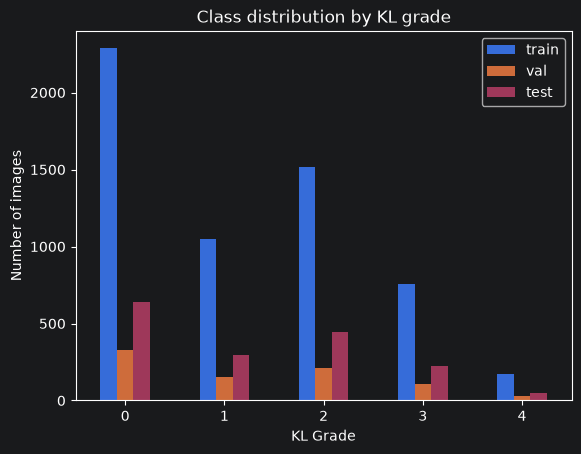

In [27]:
# Visualise class distribution - shows how many images are available for each KL grade 
# in the train, validation and test sets

counts_df.plot(kind="bar")
plt.title("Class distribution by KL grade")
plt.xlabel("KL Grade")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.show()

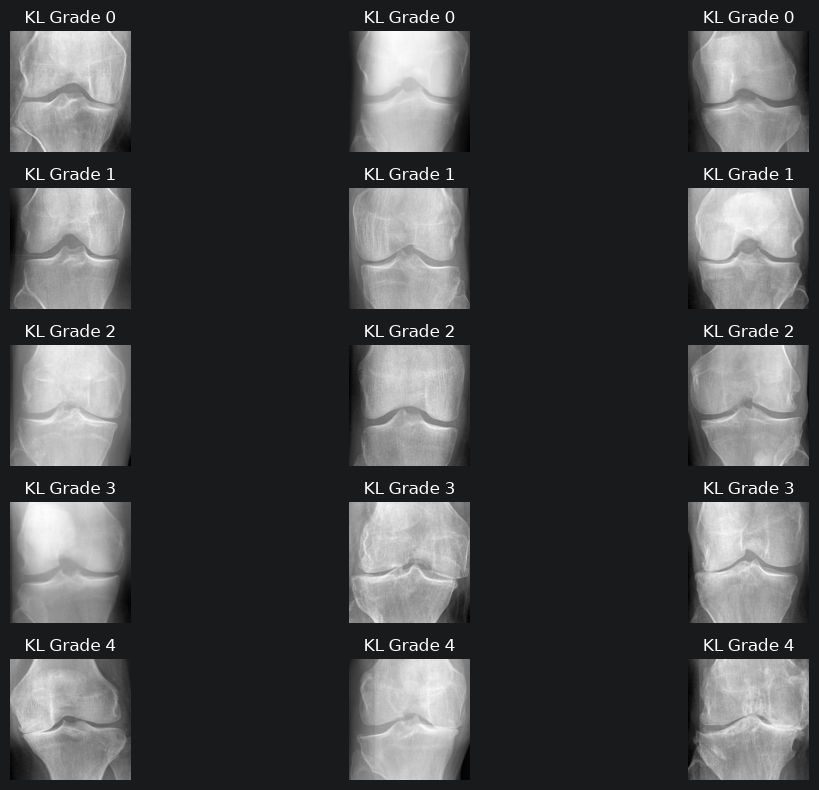

In [28]:
# Sample x-rays from each grade

import random
from PIL import Image

def show_sample_images(split_dir, n=3):
    class_folders = sorted([f for f in split_dir.iterdir() if f.is_dir()])

    plt.figure(figsize=(12, 8))

    plot_idx = 1

    for class_folder in class_folders:
        image_files = list(class_folder.glob("*"))
        selected_images = random.sample(image_files, min(n, len(image_files)))

        for img_path in selected_images:
            img = Image.open(img_path).convert("L")

            plt.subplot(len(class_folders), n, plot_idx)
            plt.imshow(img, cmap="gray")
            plt.title(f"KL Grade {class_folder.name}")
            plt.axis("off")

            plot_idx += 1

    plt.tight_layout()
    plt.show()

show_sample_images(TRAIN_DIR, n=3)

### Baseline Preprocessing

In [29]:
# Resizing and rescaling

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load training images
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="int",
    shuffle=True,
    seed=SEED
)

# Load validation images
val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="int",
    shuffle=False
)

# Load test images
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    label_mode="int",
    shuffle=False
)

Found 5778 files belonging to 5 classes.
Found 826 files belonging to 5 classes.
Found 1656 files belonging to 5 classes.


In [30]:
# Normalise pixel values from 0-255 to 0-1 - Keeps the input values on a consistent scale

normalisation_layer = layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalisation_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalisation_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalisation_layer(x), y))

This section improves the focus on the knee by doing the following: Cropping the image to be more centred around the knee, increases the contrast on the image and applies sharpening in order to make it easier for the baseline to distinguish Grade 1 from Grade 0

In [38]:
def centre_crop_image(image, crop_fraction=0.8):
    height, width = image.shape[:2]

    crop_height = int(height * crop_fraction)
    crop_width = int(width * crop_fraction)

    start_y = (height - crop_height) // 2
    start_x = (width - crop_width) // 2

    cropped = image[start_y:start_y + crop_height, start_x:start_x + crop_width]
    return cropped

def apply_clahe(image):
    image = np.asarray(image)

    if image.max() <= 1.0:
        image = image * 255.0

    image_uint8 = image.astype("uint8")


    clahe = cv2.createCLAHE(
        clipLimit=2.0, tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(image_uint8)
    return enhanced

def preprocess_knee_xray(image):
    cropped = centre_crop_image(image)
    resized = cv2.resize(cropped, (224, 224))
    enhanced = apply_clahe(resized)
    normalised = enhanced.astype("float32") / 255.0

    return normalised

In [39]:
def show_before_after(original,processed):
    plt.figure(figsize=(12, 6))

    plt.subplot(1,2,1)
    plt.imshow(original, cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(processed, cmap="gray")
    plt.title("Cropped & enhanced")
    plt.axis("off")

    plt.show()

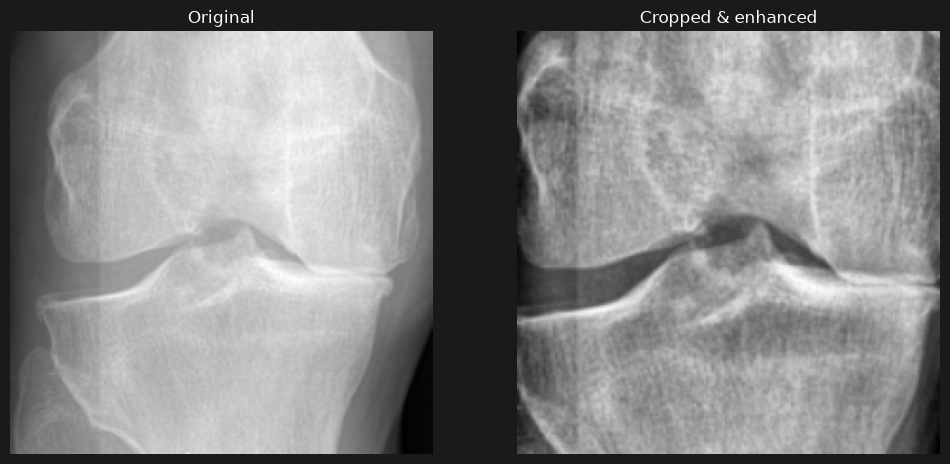

In [45]:
for images, labels in train_ds.take(1):
    images_float = tf.cast(images, tf.float32)
    image = images_float[0].numpy()
    processed = preprocess_knee_xray(image)
    show_before_after(image,processed)
    break

This baseline CNN uses three convolution blocks followed by global average pooling, a dense layer, dropout and a final five-class softmax output layer


In [46]:
# Improve speed

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [47]:
# Baseline should classify all five KL grades and be used as the comparison point for future improvements

def build_baseline_cnn():
    '''
    Baseline CNN for five-class KL grade classification

    Output classes:
    0 = Grade 0
    1 = Grade 1
    2 = Grade 2
    3 = Grade 3
    4 = Grade 4

    '''
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(224, 224, 1)),

        # First convolution block
        tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        # Second convolution block
        tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        # Third convolution block
        tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D((2, 2)),

        # Learned feature maps
        tf.keras.layers.GlobalAveragePooling2D(),

        # Fully connected classification layer 
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.3),

        # Five output neurons for KL grades 0-4
        tf.keras.layers.Dense(5, activation="softmax")
    ])

    # Compile the model
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# Create the baseline CNN and display the model architechcture
baseline_model = build_baseline_cnn()
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,829 (429.02 KB)

 Trainable params: 109,829 (429.02 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def load_preprocessed_images(split_dir, use_sharpening=False):
    images = []
    labels = []

    class_folders = sorted(
        [f for f in split_dir.iterdir() if f.is_dir()],
        key=lambda x: int(x.name)
    )

    for class_folder in class_folders:
        label = int(class_folder.name)

        for img_path in class_folder.glob("*"):
            image = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)

            if image is None:
                continue

            processed = preprocess_knee_xray(
                image,
                use_sharpening=use_sharpening
            )

            images.append(processed)
            labels.append(label)

    images = np.array(images, dtype="float32")
    labels = np.array(labels, dtype="int32")

    images = np.expand_dims(images, axis=-1)

    return images, labels


In [48]:
# Train the baseline model
# The baseline model is trained on the training dataset and monitored using the validation dataset
# This gives the first comparison point

EPOCHS = 10

history_baseline = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10


C:\Users\Warith2\PycharmProjects\-error-404-technical-challenge\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


181/181 ━━━━━━━━━━━━━━━━━━━━ 144s 786ms/step - accuracy: 0.3859 - loss: 1.4257 - val_accuracy: 0.3971 - val_loss: 1.4165
Epoch 2/10
181/181 ━━━━━━━━━━━━━━━━━━━━ 142s 782ms/step - accuracy: 0.3955 - loss: 1.4129 - val_accuracy: 0.3971 - val_loss: 1.4147
Epoch 3/10
181/181 ━━━━━━━━━━━━━━━━━━━━ 141s 781ms/step - accuracy: 0.3943 - loss: 1.4096 - val_accuracy: 0.3971 - val_loss: 1.4162
Epoch 4/10
181/181 ━━━━━━━━━━━━━━━━━━━━ 139s 767ms/step - accuracy: 0.3960 - loss: 1.4057 - val_accuracy: 0.3971 - val_loss: 1.4123
Epoch 5/10
181/181 ━━━━━━━━━━━━━━━━━━━━ 144s 798ms/step - accuracy: 0.3956 - loss: 1.4055 - val_accuracy: 0.3971 - val_loss: 1.4095
Epoch 6/10
181/181 ━━━━━━━━━━━━━━━━━━━━ 144s 798ms/step - accuracy: 0.3956 - loss: 1.4032 - val_accuracy: 0.3971 - val_loss: 1.4077
Epoch 7/10
181/181 ━━━━━━━━━━━━━━━━━━━━ 139s 770ms/step - accuracy: 0.3956 - loss: 1.4022 - val_accuracy: 0.3971 - val_loss: 1.4086
Epoch 8/10
181/181 ━━━━━━━━━━━━━━━━━━━━ 141s 779ms/step - accuracy: 0.3955 - loss: 1.40

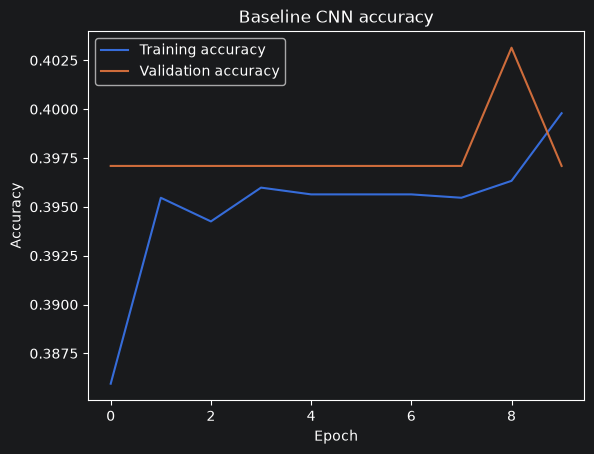

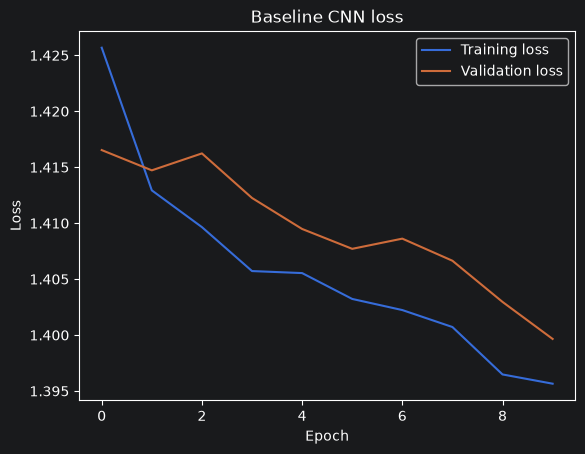

In [49]:
# Plot baseline accuracy
# Plot compares training and validation accuracy accross epochs and 
# assesses whether the model is learning and whether there is evidence of overfitting

plt.plot(history_baseline.history["accuracy"], label="Training accuracy")
plt.plot(history_baseline.history["val_accuracy"], label="Validation accuracy")
plt.title("Baseline CNN accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Plot baseline loss
plt.plot(history_baseline.history["loss"], label="Training loss")
plt.plot(history_baseline.history["val_loss"], label="Validation loss")
plt.title("Baseline CNN loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


### Evaluate the baseline model

In [50]:
# Accuracy, confusion matrix, per-class recall, KL Grade 1 recall, Quadratic Weighted Kappa

def get_predictions(model, dataset):
    '''
    Generate true labels and predicted labels for a trained model.
    
    Parameters:
    model: trained TensorFlow/Keras model
    dataset: TensorFlow dataset containing images and labels
    
    Returns:
    y_true: actual KL grade labels
    y_pred: predicted KL grade labels
    
    '''
    y_true = []
    y_pred = []

    for images, labels in dataset:

        # Predict class probabilities for each image
        probabilities = model.predict(images, verbose=0)


        # Convert the probabilities into predicted class labels
        predictions = np.argmax(probabilities, axis=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions)

    return np.array(y_true), np.array(y_pred)

In [51]:
# Apply the baseline model to the test set
baseline_y_true, baseline_y_pred = get_predictions(baseline_model, test_ds)

In [52]:
# Classification report
# The classification report gives precision, recall and F1-score for each KL grade. 
# Per-class recall is especially important because overall accuracy can hide poor performance on minority or clinically important classes.

print(classification_report(
    baseline_y_true,
    baseline_y_pred,
    target_names=["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"],
    digits=3
))

              precision    recall  f1-score   support

     Grade 0      0.390     0.956     0.554       639
     Grade 1      0.000     0.000     0.000       296
     Grade 2      0.261     0.051     0.086       447
     Grade 3      0.000     0.000     0.000       223
     Grade 4      0.000     0.000     0.000        51

    accuracy                          0.383      1656
   macro avg      0.130     0.202     0.128      1656
weighted avg      0.221     0.383     0.237      1656



C:\Users\Warith2\PycharmProjects\-error-404-technical-challenge\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Warith2\PycharmProjects\-error-404-technical-challenge\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Warith2\PycharmProjects\-error-404-technical-challenge\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parame

In [53]:
# Quadratic Weighted Kappa
# Quadratic Weighted Kappa is calculated because KL grades are ordinal. This means that the distance between predicted and true grades matters; 
# for example, predicting Grade 1 as Grade 0 is less severe than predicting Grade 1 as Grade 4.

baseline_qwk = cohen_kappa_score(
    baseline_y_true,
    baseline_y_pred,
    weights="quadratic"
)

print("Baseline Quadratic Weighted Kappa:", baseline_qwk)


Baseline Quadratic Weighted Kappa: 0.016904496808609615


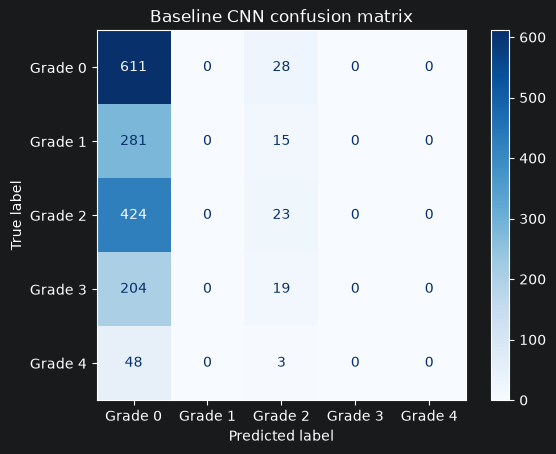

In [54]:
# Confusion Matrix
# The confusion matrix shows where the model is making correct and incorrect predictions. 
# Rows represent the true KL grade and columns represent the predicted KL grade.

cm = confusion_matrix(baseline_y_true, baseline_y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Baseline CNN confusion matrix")
plt.show()

In [55]:
# The brief says KL Grade 1 is hard because it represents “doubtful” osteoarthritis, 
# where features are subtle and even expert raters can disagree.
# Calculate Grade 1 recall

from sklearn.metrics import recall_score, precision_score

baseline_grade1_recall = recall_score(
    baseline_y_true,
    baseline_y_pred,
    labels=[1],
    average=None
)[0]

baseline_grade1_precision = precision_score(
    baseline_y_true,
    baseline_y_pred,
    labels=[1],
    average=None
)[0]

print("Baseline Grade 1 recall:", baseline_grade1_recall)
print("Baseline Grade 1 precision:", baseline_grade1_precision)



Baseline Grade 1 recall: 0.0
Baseline Grade 1 precision: 0.0


C:\Users\Warith2\PycharmProjects\-error-404-technical-challenge\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [56]:
# Inspect where true Grade 1 images were predicted
# This section examines the predictions for images that were truly KL Grade 1. 
#This helps identify whether early-stage OA is being confused with healthy knees or with more advanced grades.

grade1_indices = np.where(baseline_y_true == 1)[0]
grade1_predictions = baseline_y_pred[grade1_indices]

pd.Series(grade1_predictions).value_counts().sort_index()


0    281
2     15
Name: count, dtype: int64

The baseline CNN achieved an accuracy of 0.379. However, the confusion matrix showed that the model predicted almost all images as Grade 0.

All 296 true Grade 1 images were misclassified as Grade 0, giving a Grade 1 recall of 0.0. This suggests that the baseline model failed to distinguish subtle early-stage osteoarthritic features from radiographically healthy knees.

The Quadratic Weighted Kappa was 0.0178, indicating very poor ordinal agreement. This confirms that accuracy alone is not sufficient for this task and supports the need for targeted improvements focused on Grade 1 detection.

In [57]:
# Create a results table

results = []

results.append({
    "model": "Baseline CNN",
    "preprocessing": "Resize + rescale only",
    "architecture": "Simple CNN",
    "accuracy": np.mean(baseline_y_true == baseline_y_pred),
    "qwk": baseline_qwk,
    "grade1_recall": baseline_grade1_recall,
    "grade1_precision": baseline_grade1_precision
})

results_df = pd.DataFrame(results)
results_df


,model,preprocessing,architecture,accuracy,qwk,grade1_recall,grade1_precision
0,Baseline CNN,Resize + rescale only,Simple CNN,0.38285,0.016904,0.0,0.0


In [22]:
Path("outputs/results").mkdir(parents=True, exist_ok=True)
results_df.to_csv("outputs/results/baseline_results_table.csv", index=False)